# Data Structures & Algorithms: Complexity Analysis and Recursion

> **Who is this for:** anyone who has finished the Python basics and wants to understand *why* some code is fast and some is slow. Also for university students revising for a DSA exam and for anyone preparing for coding interviews.
>
> **What you will learn:**
> - What an algorithm is, the RAM model of computation and how to count operations
> - Big-O, Big-Θ, Big-Ω (with the constants *c* and *n₀*), plus little-o
> - Common growth rates and what they mean in real seconds for n = 10⁶
> - Best / average / worst case, amortized analysis, space complexity and the time vs. space trade-off
> - How to time code with `timeit` and estimate its growth exponent from a log-log plot
> - Recursion: base case, call stack, recursion trees, tail recursion, the recursion limit, memoisation
> - Solving recurrences: substitution, recursion trees and the Master theorem
> - The cost of every common operation on `list`, `dict`, `set` and `deque`
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb) (functions, loops, lists). High-school algebra (powers and logarithms). The [maths notation bridge](../../14_Mathematics/00_start_here_math_notation_bridge.ipynb) helps if Σ or log look scary.
>
> **Time needed:** about 2–3 hours.
>
> **Runs on:** CPU, no API key, no internet.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows the order of the GeeksforGeeks DSA tutorial and a typical university DSA course (CLRS chapters 1–4).

## Explained simply

An **algorithm** is just a recipe: a list of exact steps that turns an input into an answer. Two recipes can give the same answer but take very different amounts of work, and this notebook teaches you how to measure that work *before* you run anything. We don't count seconds (those depend on the computer); we count how the number of steps **grows** when the input gets bigger. That growth is written with **Big-O**, e.g. O(n) means "double the input, double the work". **Recursion** is when a recipe uses a smaller copy of itself, like a set of Russian dolls, and we will see how to work out its cost too.

**Everyday examples**
- Finding a name in a messy pile of 1,000 exam papers means checking them one by one (up to 1,000 looks). Finding it in an alphabetically sorted pile means opening in the middle and halving (about 10 looks). Same task, very different growth.
- Shaking hands: if everyone in a room shakes hands with everyone else, 10 people make 45 handshakes but 100 people make 4,950. Ten times more people, about a hundred times more work: that is O(n²).

**Tiny example.** You want to know if the number 7 is in the list `[3, 9, 7, 1]`. Checking one by one, you look at 3, then 9, then 7: found after 3 looks. In the worst case (the number isn't there) you would look at all 4. For a list of n numbers the worst case is n looks, so this search is **O(n)**.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Big-O | how fast the work grows as the input grows | "will my model training still finish if the data is 10× bigger?" |
| Recursion | solve a problem using a smaller copy of the same problem | folders inside folders; decision trees; game-tree search |
| Amortized cost | an occasional expensive step averaged over many cheap ones | Python `list.append`; a growing chat history (KV cache) in an LLM server |

## Table of contents
1. What is an algorithm? The RAM model and counting operations
2. Asymptotic notation: Big-O, Big-Ω, Big-Θ, little-o
3. Common growth rates (with real time estimates)
4. Best, average and worst case; amortized analysis
5. Space complexity and the time vs. space trade-off
6. Measuring for real: `timeit` and log-log plots
7. Recursion: the call stack, recursion trees, tail recursion, memoisation
8. Recurrence relations and the Master theorem
9. Complexity of Python's built-in data structures
10. How this connects to modern AI
11. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. What is an algorithm?

> 💡 **In plain English:** an algorithm is a precise recipe, and we judge it by counting how many basic steps it takes.

**Intuition.** A recipe is an algorithm for a cake: a finite list of clear steps that turns ingredients (input) into a cake (output). If a step says "add some sugar", it is not precise enough for a computer.

An **algorithm** is a finite sequence of well-defined instructions that takes some **input** and produces an **output**, solving a specific problem. Knuth lists five properties:

| Property | Meaning |
|---|---|
| **Finiteness** | it always stops after a finite number of steps |
| **Definiteness** | every step is precisely defined (no "some sugar") |
| **Input** | zero or more inputs |
| **Output** | one or more outputs |
| **Effectiveness** | every step is basic enough to be carried out exactly |

A **data structure** is a way to organise data in memory so that certain operations (search, insert, delete…) are efficient. Algorithms and data structures always come together: the same problem can be easy or hard depending on how the data is stored.

### The RAM model

To compare algorithms without caring whether your laptop is fast or slow, we use an idealised computer, the **Random Access Machine (RAM) model**:
- each simple operation (`+`, `-`, `*`, compare, assign, read/write one memory cell, follow one pointer) costs **1 time unit**;
- memory access to any cell takes the same constant time ("random access");
- loops and function calls are *not* simple: their cost is the sum of the steps inside.

The **running time** T(n) is then the number of simple operations executed as a function of the input size n. It is a model, not reality (real machines have caches, and Python operations are not all equal), but it predicts *how running time grows*, which is what matters for large inputs.

### Counting operations by hand

```
def total(a):              # cost   times executed
    s = 0                  #  1      1
    for x in a:            #  1      n      (fetch the next element)
        s = s + x          #  2      n      (one add, one assign)
    return s               #  1      1
```
T(n) = 1 + n + 2n + 1 = **3n + 2**. The exact constants depend on what we choose to count, but the shape "a constant times n" does not. That is why we will soon drop constants altogether.

In [2]:
# Let's count operations automatically by instrumenting the code.
def total_counted(a):
    ops = 0
    s = 0; ops += 1                 # assignment
    for x in a:
        ops += 1                    # loop step: fetch next element
        s = s + x; ops += 2         # addition + assignment
    ops += 1                        # return
    return s, ops

def all_pairs_counted(a):
    """Count how many times the inner body of a double loop runs."""
    ops = 0
    n = len(a)
    for i in range(n):
        for j in range(i + 1, n):   # every unordered pair (i, j) with i < j
            ops += 1                # one comparison a[i] vs a[j]
    return ops

rows = []
for n in [1, 10, 100, 1000]:
    _, t1 = total_counted(list(range(n)))
    t2 = all_pairs_counted(list(range(n)))
    rows.append({"n": n, "total(): counted": t1, "3n + 2": 3 * n + 2,
                 "pairs: counted": t2, "n(n-1)/2": n * (n - 1) // 2})
    assert t1 == 3 * n + 2 and t2 == n * (n - 1) // 2   # our hand formulas are exact
pd.DataFrame(rows)

,n,total(): counted,3n + 2,pairs: counted,n(n-1)/2
0,1,5,5,0,0
1,10,32,32,45,45
2,100,302,302,4950,4950
3,1000,3002,3002,499500,499500


**What just happened?** The instrumented functions counted exactly **3n + 2** operations for the single loop and **n(n−1)/2** comparisons for the double loop, matching our hand analysis. Notice how differently they grow: at n = 1000 the single loop does about 3 thousand operations, the double loop about half a million. The constant 3 hardly matters; the *power of n* does.

---
## 2. Asymptotic notation: Big-O, Big-Ω, Big-Θ

> 💡 **In plain English:** Big-O, Big-Ω and Big-Θ say how fast the work grows, ignoring small details like constant factors.

**Intuition.** When comparing two runners over a marathon, the first 10 metres do not matter. Asymptotic notation compares functions "in the long run" (large n) and ignores constant factors, which depend on hardware and language anyway.

Let f(n) and g(n) be non-negative functions of n.

| Notation | Read as | Formal definition | Analogy |
|---|---|---|---|
| **f(n) = O(g(n))** | "big-O": upper bound | ∃ c > 0, n₀ ≥ 1 such that **0 ≤ f(n) ≤ c·g(n) for all n ≥ n₀** | f ≤ g |
| **f(n) = Ω(g(n))** | "big-Omega": lower bound | ∃ c > 0, n₀ ≥ 1 such that **0 ≤ c·g(n) ≤ f(n) for all n ≥ n₀** | f ≥ g |
| **f(n) = Θ(g(n))** | "big-Theta": tight bound | ∃ c₁, c₂ > 0, n₀ such that **c₁·g(n) ≤ f(n) ≤ c₂·g(n) for all n ≥ n₀** | f = g |
| **f(n) = o(g(n))** | "little-o": strictly smaller | for **every** c > 0 there is an n₀ with f(n) < c·g(n) for n ≥ n₀ (equivalently lim f/g = 0) | f < g |
| **f(n) = ω(g(n))** | "little-omega": strictly larger | lim f/g = ∞ | f > g |

Key facts:
- f = Θ(g) **if and only if** f = O(g) and f = Ω(g).
- "=" here really means "∈": O(g) is a *set* of functions. 3n + 2 = O(n) and also 3n + 2 = O(n²) (a loose but true upper bound).
- Constants and lower-order terms vanish: 3n² + 10n + 5 = Θ(n²).
- n = o(n²) but n² ≠ o(n²) (little-o is *strict*).

### Worked example by hand
Show f(n) = 3n² + 10n + 5 is Θ(n²).
- **Upper bound (O):** choose c₂ = 4. We need 3n² + 10n + 5 ≤ 4n², i.e. n² − 10n − 5 ≥ 0. The positive root is 5 + √30 ≈ 10.48, so it holds for all **n ≥ 11 → n₀ = 11**.
- **Lower bound (Ω):** choose c₁ = 3. 3n² ≤ 3n² + 10n + 5 holds for all n ≥ 1.
- So with c₁ = 3, c₂ = 4, n₀ = 11 the definition of Θ is satisfied.

(Other constants work too, e.g. c₂ = 18 with n₀ = 1, since 3n² + 10n² + 5n² = 18n² ≥ f(n) for n ≥ 1. The definition only needs *some* pair.)

smallest n0 for the upper bound with c2 = 4: 11


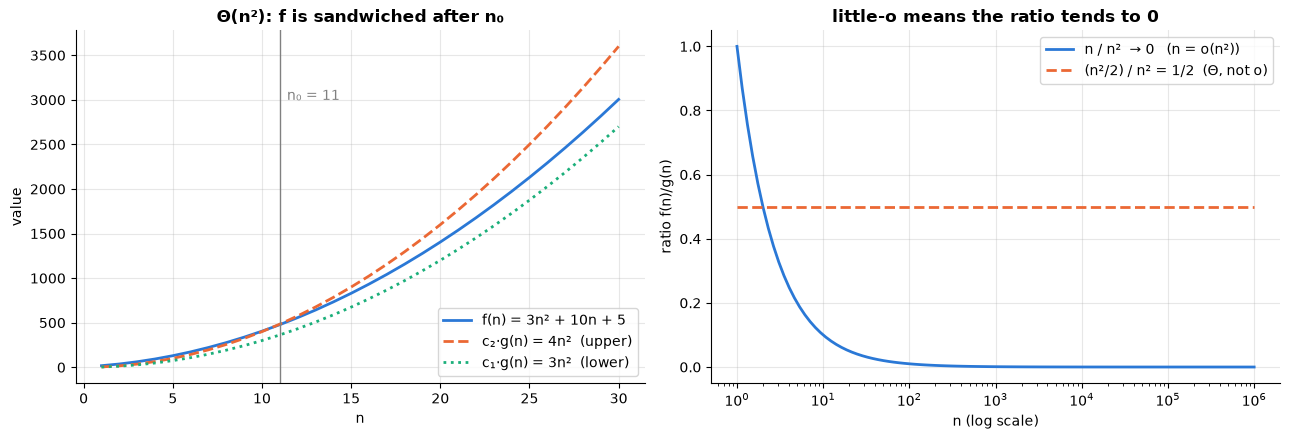

In [3]:
f  = lambda n: 3 * n**2 + 10 * n + 5      # the function we analyse
g  = lambda n: n**2                        # the simple "shape" we compare against
c1, c2 = 3, 4

# Find the smallest n0 from which c2*g(n) >= f(n) holds (check far beyond, to be safe)
n0 = next(n for n in range(1, 1000) if all(f(m) <= c2 * g(m) for m in range(n, 5000)))
print("smallest n0 for the upper bound with c2 = 4:", n0)
assert n0 == 11
assert all(c1 * g(n) <= f(n) <= c2 * g(n) for n in range(n0, 100_000))   # Theta holds

ns = np.arange(1, 31)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ns, f(ns), label="f(n) = 3n² + 10n + 5", color=PALETTE[0])
ax[0].plot(ns, c2 * g(ns), "--", label="c₂·g(n) = 4n²  (upper)", color=PALETTE[1])
ax[0].plot(ns, c1 * g(ns), ":", label="c₁·g(n) = 3n²  (lower)", color=PALETTE[2])
ax[0].axvline(n0, color="grey", lw=1); ax[0].text(n0 + 0.4, 3000, "n₀ = 11", color="grey")
ax[0].set(title="Θ(n²): f is sandwiched after n₀", xlabel="n", ylabel="value")
ax[0].legend()

# little-o: n / n^2 -> 0 but (n^2/2) / n^2 stays at 1/2
big = np.logspace(0, 6, 100)
ax[1].semilogx(big, big / big**2, label="n / n²  → 0   (n = o(n²))", color=PALETTE[0])
ax[1].semilogx(big, (big**2 / 2) / big**2, "--", label="(n²/2) / n² = 1/2  (Θ, not o)", color=PALETTE[1])
ax[1].set(title="little-o means the ratio tends to 0", xlabel="n (log scale)", ylabel="ratio f(n)/g(n)")
ax[1].legend()
plt.tight_layout(); plt.show()

**What just happened?** The code searched for the smallest n₀ and found **n₀ = 11**, the same value we derived by hand. On the left, before n = 11 the blue curve f(n) is *above* 4n²; after it, f stays between 3n² and 4n² forever. On the right, the ratio n/n² goes to 0 (so n = o(n²)), while (n²/2)/n² stays at ½ (so n²/2 = Θ(n²) but not o(n²)).

> ⚠️ **Common mistake:** "Big-O means worst case". No! O, Ω and Θ are about *bounding functions*. Worst-case, best-case and average-case are *different functions* (see section 4), and each can be described with O, Ω or Θ. For example, insertion sort's best case is Θ(n) and its worst case is Θ(n²).

> 🎓 **Exam / interview tip:** in interviews "O(...)" is usually used loosely to mean the tight bound Θ. In an exam, if asked to *prove* f = O(g), always state explicit c and n₀ and show the inequality.

---
## 3. Common growth rates

> 💡 **In plain English:** some growth rates are harmless (log n), some are fine (n log n), and some are hopeless for big inputs (2ⁿ).

From slowest-growing to fastest-growing:

| Growth | Name | Typical example |
|---|---|---|
| 1 | constant | index into an array, dict lookup (average) |
| log n | logarithmic | binary search, one operation on a balanced BST / heap |
| n | linear | scan a list, find the max |
| n log n | linearithmic | merge sort, heap sort, `sorted()` |
| n² | quadratic | all pairs, bubble / insertion sort |
| n³ | cubic | naive matrix multiplication, Floyd–Warshall |
| 2ⁿ | exponential | all subsets, naive recursive Fibonacci (≈1.618ⁿ) |
| n! | factorial | all permutations, brute-force travelling salesman |

Below we turn these into **real time for n = 10⁶**, assuming a machine that performs 10⁸ simple operations per second (a reasonable rule of thumb for compiled C/C++; pure Python loops are roughly 10–100× slower).

In [4]:
OPS_PER_SEC = 1e8          # assumed simple operations per second
n = 10**6

def human(seconds):
    """Turn seconds into a readable string, including astronomically large values."""
    if seconds < 1e-6:  return f"{seconds * 1e9:.1f} ns"
    if seconds < 1e-3:  return f"{seconds * 1e6:.1f} µs"
    if seconds < 1:     return f"{seconds * 1e3:.1f} ms"
    if seconds < 60:    return f"{seconds:.1f} s"
    if seconds < 3600:  return f"{seconds / 60:.1f} min"
    if seconds < 86400: return f"{seconds / 3600:.1f} hours"
    years = seconds / (365.25 * 86400)
    if years < 1e6:     return f"{years:,.0f} years"
    return f"10^{math.log10(years):,.0f} years"

# log10 of the number of operations (so 2^n and n! do not overflow)
growth = {
    "1":       0.0,
    "log₂ n":  math.log10(math.log2(n)),
    "n":       math.log10(n),
    "n log₂ n": math.log10(n * math.log2(n)),
    "n²":      2 * math.log10(n),
    "n³":      3 * math.log10(n),
    "2ⁿ":      n * math.log10(2),
    "n!":      math.lgamma(n + 1) / math.log(10),   # log10(n!) via the log-gamma function
}
table = pd.DataFrame({
    "growth": list(growth),
    "operations (n = 10⁶)": [f"10^{v:,.1f}" for v in growth.values()],
    "time at 10⁸ ops/s": [human(10**(v - 8)) if v < 300 else
                          f"10^{(v - 8 - math.log10(365.25 * 86400)):,.0f} years"
                          for v in growth.values()],
})
table

,growth,operations (n = 10⁶),time at 10⁸ ops/s
0,1,10^0.0,10.0 ns
1,log₂ n,10^1.3,199.3 ns
2,n,10^6.0,10.0 ms
3,n log₂ n,10^7.3,199.3 ms
4,n²,10^12.0,2.8 hours
5,n³,10^18.0,317 years
6,2ⁿ,"10^301,030.0","10^301,014 years"
7,n!,"10^5,565,708.9","10^5,565,693 years"


**What just happened?** For a million items: log n is instant (≈20 operations), n log n takes about 0.2 seconds, n² already takes **about 2.8 hours**, n³ about **317 years** and 2ⁿ or n! take a number of years with hundreds of thousands of digits. (For comparison the universe is about 1.4 × 10¹⁰ years old.) This is why the algorithm matters far more than the hardware: a 1000× faster computer turns 2.8 hours into 10 seconds, but turns the exponential row into... still forever.

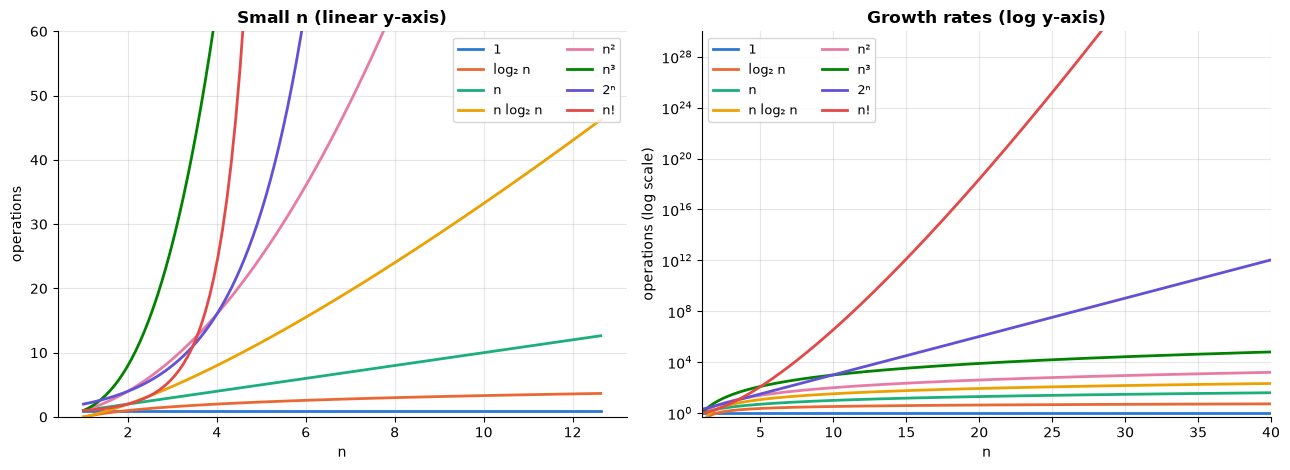

In [5]:
ns = np.linspace(1, 40, 400)
curves = {
    "1": np.ones_like(ns), "log₂ n": np.log2(ns), "n": ns, "n log₂ n": ns * np.log2(ns),
    "n²": ns**2, "n³": ns**3, "2ⁿ": 2.0**ns,
    "n!": np.exp([math.lgamma(v + 1) for v in ns]),
}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for (name, y), col in zip(curves.items(), PALETTE):
    ax[0].plot(ns[:120], y[:120], label=name, color=col)          # small n, linear scale
    ax[1].semilogy(ns, y, label=name, color=col)                   # larger n, log scale
ax[0].set(ylim=(0, 60), title="Small n (linear y-axis)", xlabel="n", ylabel="operations")
ax[0].legend(ncol=2, fontsize=9)
ax[1].set(ylim=(0.5, 1e30), xlim=(1, 40), title="Growth rates (log y-axis)", xlabel="n", ylabel="operations (log scale)")
ax[1].legend(ncol=2, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

**What just happened?** On the left (tiny n) the curves are tangled: for n < 10, 2ⁿ is actually *smaller* than n³. On the right (log scale) the order becomes clear and never changes again: 1 < log n < n < n log n < n² < n³ < 2ⁿ < n!. For *small* inputs a "worse" algorithm with small constants can win, which is why real libraries switch to insertion sort for tiny sub-arrays (you will see this in Timsort, notebook 03).

---
## 4. Best, average and worst case

> 💡 **In plain English:** the same algorithm can be lucky or unlucky with its input, and occasional expensive steps can average out to cheap.

For the same n, different inputs can take different time. **Linear search** for a target in a list of n items:

| Case | When | Comparisons | Bound |
|---|---|---|---|
| **Best case** | target is at index 0 | 1 | Θ(1) |
| **Worst case** | target is last or absent | n | Θ(n) |
| **Average case** | target equally likely at each of the n positions | (1 + 2 + … + n)/n = (n + 1)/2 | Θ(n) |

- **Worst case** is the usual guarantee ("it will never be slower than this").
- **Average case** needs an assumption about the input distribution (here: uniform position).
- **Best case** is rarely useful on its own (any algorithm can be fast on a lucky input).

In [6]:
def linear_search_count(a, target):
    """Return (index, number_of_comparisons)."""
    comparisons = 0
    for i, x in enumerate(a):
        comparisons += 1
        if x == target:
            return i, comparisons
    return -1, comparisons

n = 1000
a = list(range(n))
best = linear_search_count(a, 0)[1]
worst = linear_search_count(a, -5)[1]                      # absent element
avg = np.mean([linear_search_count(a, random.randrange(n))[1] for _ in range(20_000)])
print(f"best = {best}, worst = {worst}, average over 20,000 random targets = {avg:.1f}, theory (n+1)/2 = {(n + 1) / 2}")
assert best == 1 and worst == n and abs(avg - (n + 1) / 2) < 15

best = 1, worst = 1000, average over 20,000 random targets = 500.2, theory (n+1)/2 = 500.5


**What just happened?** The best case needed 1 comparison, the worst 1000, and the empirical average landed within a few comparisons of the theoretical (n + 1)/2 = 500.5.

### Amortized analysis: why `list.append` is O(1)

A Python list is a **dynamic array**: a contiguous block with some spare *capacity*. When it is full, appending forces a **resize**: allocate a bigger block and copy every element (cost n). So *one* append can be O(n). Is append then O(n)? No: **amortized analysis** looks at the *total* cost of a sequence of operations and divides by the number of operations.

**Doubling strategy, by hand.** Start with capacity 1 and double when full. Appending n = 8 items:

| append # | capacity before | copies | total copies so far |
|---|---|---|---|
| 1 | 1 | 0 | 0 |
| 2 | 1 → 2 | 1 | 1 |
| 3 | 2 → 4 | 2 | 3 |
| 4 | 4 | 0 | 3 |
| 5 | 4 → 8 | 4 | 7 |
| 6–8 | 8 | 0 | 7 |

Total copies = 1 + 2 + 4 + … < 2n. So n appends cost at most n (writes) + 2n (copies) = 3n, i.e. **O(1) amortized per append** even though a single append can be O(n). (This is the *aggregate method*; CLRS chapter 16 also covers the accounting and potential methods.)

Let's build our own dynamic array and *measure* this.

2000 appends: total cost = 4047, total copies = 2047, max single append = 1025, average = 2.02


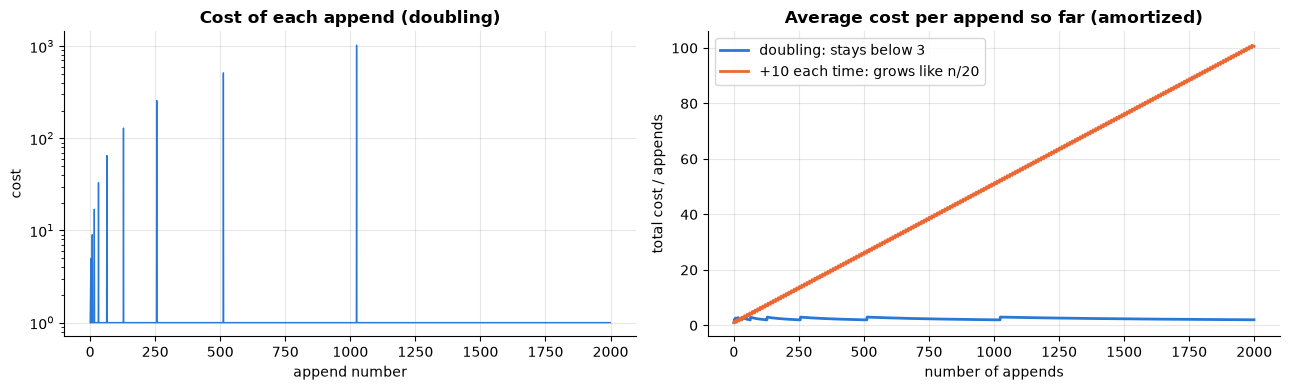

In [7]:
class DynamicArray:
    """A minimal dynamic array that doubles its capacity when full."""
    def __init__(self, growth=2.0):
        self.capacity = 1
        self.size = 0
        self.data = [None] * self.capacity   # pretend this is a fixed-size block of memory
        self.growth = growth
        self.copies = 0                      # total elements copied during resizes

    def append(self, value):
        cost = 1                             # writing the new element
        if self.size == self.capacity:       # full: allocate a bigger block and copy
            new_cap = max(self.capacity + 1, int(self.capacity * self.growth))
            new_data = [None] * new_cap
            for i in range(self.size):       # copy every existing element: O(size)
                new_data[i] = self.data[i]
            self.copies += self.size
            cost += self.size
            self.data, self.capacity = new_data, new_cap
        self.data[self.size] = value
        self.size += 1
        return cost                          # the actual cost of THIS append

    def __getitem__(self, i):
        if not 0 <= i < self.size:
            raise IndexError(i)
        return self.data[i]

n = 2000
arr = DynamicArray()
costs = [arr.append(i) for i in range(n)]
assert [arr[i] for i in range(n)] == list(range(n))           # it behaves like a list
print(f"{n} appends: total cost = {sum(costs)}, total copies = {arr.copies}, "
      f"max single append = {max(costs)}, average = {sum(costs) / n:.2f}")
assert arr.copies < 2 * n and sum(costs) <= 3 * n             # the amortized bound holds

# Compare with growing by a constant (+10) instead of doubling
arr_add = DynamicArray(growth=1.0)
def append_add10(self, v):
    cost = 1
    if self.size == self.capacity:
        self.data += [None] * 10; self.copies += self.size; cost += self.size
        self.capacity += 10
    self.data[self.size] = v; self.size += 1
    return cost
costs_add = [append_add10(arr_add, i) for i in range(n)]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(costs, color=PALETTE[0], lw=1)
ax[0].set(title="Cost of each append (doubling)", xlabel="append number", ylabel="cost", yscale="log")
ax[1].plot(np.cumsum(costs) / np.arange(1, n + 1), label="doubling: stays below 3", color=PALETTE[0])
ax[1].plot(np.cumsum(costs_add) / np.arange(1, n + 1), label="+10 each time: grows like n/20", color=PALETTE[1])
ax[1].set(title="Average cost per append so far (amortized)", xlabel="number of appends", ylabel="total cost / appends")
ax[1].legend(); plt.tight_layout(); plt.show()

**What just happened?** With doubling, a few appends were expensive (the spikes at powers of two, the largest copying 1024 elements) but the *average* stayed below 3, exactly as the analysis predicted (total copies < 2n). Growing by a fixed +10 instead makes the average grow linearly with n, so n appends cost Θ(n²) in total. **Geometric growth is the key**, not the exact factor 2.

CPython's real list uses a smaller growth factor (about 1.125 plus a small constant) to waste less memory. Let's watch it with `sys.getsizeof`, and time real appends.

In [8]:
lst, sizes, jumps = [], [], []
prev = sys.getsizeof(lst)
for i in range(2000):
    lst.append(i)
    s = sys.getsizeof(lst)
    if s != prev:                                          # the list was reallocated
        jumps.append((len(lst), (s - sys.getsizeof([])) // 8))   # (length, slots of capacity), 8 bytes per pointer
        prev = s
caps = [c for _, c in jumps]
ratios = [b / a for a, b in zip(caps[-8:], caps[-7:])]
print("first reallocations (length → capacity):", jumps[:8])
print("growth ratio of the last few reallocations:", [round(r, 3) for r in ratios])
print("number of reallocations for 2000 appends:", len(jumps))

# Time per append stays constant as the list grows (amortized O(1))
for n in [10_000, 100_000, 1_000_000]:
    t = min(timeit.repeat(f"a = []\nfor i in range({n}): a.append(i)", number=1, repeat=5))
    print(f"n = {n:>9,}: {t / n * 1e9:6.1f} ns per append")

first reallocations (length → capacity): [(1, 4), (5, 8), (9, 16), (17, 24), (25, 32), (33, 40), (41, 52), (53, 64)]
growth ratio of the last few reallocations: [1.13, 1.132, 1.131, 1.129, 1.128, 1.129, 1.128]
number of reallocations for 2000 appends: 33
n =    10,000:   76.7 ns per append
n =   100,000:  143.4 ns per append


n = 1,000,000:   93.9 ns per append


**What just happened?** CPython reallocates only a few dozen times for 2000 appends and grows the capacity by roughly 12.5% each time (the printed ratios are about 1.12–1.13). That is still *geometric* growth, so appends remain O(1) amortized, which the timing confirms: the time per append is tens of nanoseconds and stays roughly flat: it does not grow 100× when n grows 100×. (Some drift between rows comes from CPU caches, memory allocation and other programs running at the same time, not from the algorithm.)

> 🎓 **Exam / interview tip:** "amortized O(1)" is a statement about a *sequence* of operations, with no probability involved. "Average O(1)" (e.g. dict lookup) is about random inputs/hashes. Don't mix them up.

---
## 5. Space complexity and the time vs. space trade-off

> 💡 **In plain English:** memory is a cost too, and you can often spend more memory to save time.

**Space complexity** is how much memory an algorithm needs as a function of n. We usually report the **auxiliary space**: the *extra* memory beyond the input itself.

| Function | Extra memory | Auxiliary space |
|---|---|---|
| reverse a list in place by swapping | two indices | O(1) |
| `a[::-1]` (new reversed copy) | a whole new list | O(n) |
| recursive sum of a list | one stack frame per element | O(n) (the call stack counts!) |
| merge sort | temporary arrays | O(n) |

**Time vs. space trade-off.** You can often buy speed with memory. Example: *does a list contain a duplicate?*

| Approach | Time | Extra space |
|---|---|---|
| compare all pairs | O(n²) | O(1) |
| sort a copy, then check neighbours | O(n log n) | O(n) (the copy; O(1) if sorting in place is allowed) |
| remember what you've seen in a `set` | O(n) average | O(n) |

In [9]:
import tracemalloc

def reverse_in_place(a):
    i, j = 0, len(a) - 1
    while i < j:                      # swap ends, move inwards
        a[i], a[j] = a[j], a[i]
        i += 1; j -= 1
    return a

def peak_extra_bytes(fn, arg):
    tracemalloc.start()
    fn(arg)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak

data = list(range(200_000))
print(f"in-place reverse : peak extra memory ≈ {peak_extra_bytes(reverse_in_place, data) / 1024:8.1f} KiB")
print(f"a[::-1] copy     : peak extra memory ≈ {peak_extra_bytes(lambda a: a[::-1], data) / 1024:8.1f} KiB")
assert reverse_in_place(list(range(10))) == list(range(9, -1, -1))

# Three duplicate detectors: same answer, different time/space
def has_dup_pairs(a):
    return any(a[i] == a[j] for i in range(len(a)) for j in range(i + 1, len(a)))
def has_dup_sort(a):
    b = sorted(a)
    return any(b[i] == b[i + 1] for i in range(len(b) - 1))
def has_dup_set(a):
    seen = set()
    for x in a:
        if x in seen:
            return True
        seen.add(x)
    return False

for _ in range(300):                                 # random tests against each other
    a = [random.randrange(50) for _ in range(random.randrange(0, 12))]
    assert has_dup_pairs(a) == has_dup_sort(a) == has_dup_set(a) == (len(set(a)) != len(a))

a = random.sample(range(10**7), 3000)                # 3000 distinct numbers (worst case: no duplicate)
for fn in (has_dup_pairs, has_dup_sort, has_dup_set):
    t = min(timeit.repeat(lambda: fn(a), number=1, repeat=3))
    print(f"{fn.__name__:14s}: {t * 1000:8.2f} ms")

in-place reverse : peak extra memory ≈      0.6 KiB
a[::-1] copy     : peak extra memory ≈   1562.5 KiB


has_dup_pairs :  1391.90 ms
has_dup_sort  :     1.59 ms
has_dup_set   :     0.60 ms


**What just happened?** Reversing in place needed essentially no extra memory, while `a[::-1]` allocated a second list of 200,000 pointers (about 1.5 MiB). For duplicate detection all three functions agree on 300 random tests, but on 3000 distinct numbers the O(n²) version is orders of magnitude (hundreds to thousands of times) slower than the set version; the set buys that speed with O(n) extra memory.

---
## 6. Measuring for real: `timeit` and log-log plots

> 💡 **In plain English:** theory predicts, measurement checks: time your code at several sizes and read the growth off a log-log plot.

Theory predicts growth; measurement checks it. Rules for honest timing:
1. Use **`timeit`** (it disables garbage collection and uses a high-resolution clock).
2. Repeat several times and take the **minimum** (other programs only ever make it slower).
3. Use input sizes spanning at least a factor of 10–100.

**Why log-log?** If T(n) ≈ c·nᵏ then log T = log c + k·log n: a straight line whose **slope is the exponent k**. Fitting a line to (log n, log T) estimates k. An n log n algorithm gives a slope slightly above 1.

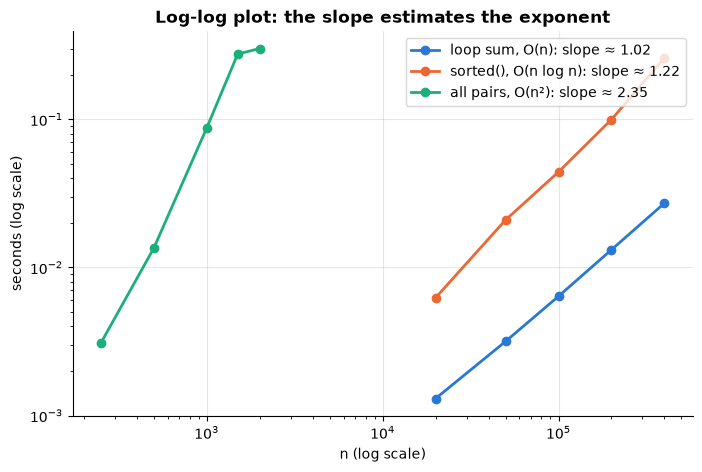

{'loop sum, O(n)': np.float64(1.02), 'sorted(), O(n log n)': np.float64(1.22), 'all pairs, O(n²)': np.float64(2.35)}


In [10]:
def time_fn(fn, make_input, sizes, repeat=5):
    """Minimum time over `repeat` runs for each input size."""
    out = []
    for n in sizes:
        data = make_input(n)
        out.append(min(timeit.repeat(lambda: fn(data), number=1, repeat=repeat)))
    return np.array(out)

def count_pairs_less(a):                 # O(n^2): compare every pair
    c = 0
    for i in range(len(a)):
        ai = a[i]
        for j in range(i + 1, len(a)):
            if ai < a[j]:
                c += 1
    return c

def python_sum(a):                       # O(n): one pass
    s = 0
    for x in a:
        s += x
    return s

experiments = {
    "loop sum, O(n)":        (python_sum,       [20_000, 50_000, 100_000, 200_000, 400_000]),
    "sorted(), O(n log n)":  (sorted,           [20_000, 50_000, 100_000, 200_000, 400_000]),
    "all pairs, O(n²)":      (count_pairs_less, [250, 500, 1000, 1500, 2000]),
}
fig, ax = plt.subplots(figsize=(8, 5))
slopes = {}
for (name, (fn, sizes)), col in zip(experiments.items(), PALETTE):
    t = time_fn(fn, lambda n: [random.random() for _ in range(n)], sizes)
    k, logc = np.polyfit(np.log(sizes), np.log(t), 1)       # slope of the log-log line
    slopes[name] = k
    ax.loglog(sizes, t, "o-", color=col, label=f"{name}: slope ≈ {k:.2f}")
ax.set(title="Log-log plot: the slope estimates the exponent", xlabel="n (log scale)", ylabel="seconds (log scale)")
ax.legend(); plt.show()
print({k: round(v, 2) for k, v in slopes.items()})
# Loose checks (timings are noisy, especially on a busy machine): linear ≈ 1, quadratic ≈ 2, and clearly apart
assert 0.5 < slopes["loop sum, O(n)"] < 1.6 and 0.5 < slopes["sorted(), O(n log n)"] < 1.8
assert 1.4 < slopes["all pairs, O(n²)"] < 2.8
assert slopes["all pairs, O(n²)"] > slopes["loop sum, O(n)"] + 0.5

**What just happened?** Each algorithm became a straight line on the log-log plot. The fitted slopes are close to 1 for the linear loop, a bit above 1 for `sorted()` (the extra log n factor, plus cache effects on larger lists) and close to 2 for the all-pairs loop. Measured slopes are never exact (caches, memory allocation, timer noise), but they reliably separate O(n) from O(n²).

> ⚠️ **Common mistake:** timing a function once on one input size and calling it "fast". A single number tells you nothing about growth. Always vary n.

---
## 7. Recursion

> 💡 **In plain English:** a recursive function solves a problem by calling itself on a smaller piece until it reaches a trivial case.

**Intuition.** Russian dolls: to count the dolls, open the outer one and count the dolls inside it (a smaller version of the same problem), then add one. When you reach the solid doll, you stop.

A **recursive function** calls itself on a smaller input. It needs:
1. a **base case**: an input small enough to answer directly (the solid doll), and
2. a **recursive case**: reduce the problem, call yourself, combine the result,
3. **progress**: each call must move towards the base case, otherwise it never stops.

```
factorial(n) = 1                       if n <= 1     (base case)
factorial(n) = n * factorial(n - 1)    otherwise     (recursive case)
```

### The call stack
Each call gets a **stack frame** (its own local variables and where to return). Frames are pushed when a function is called and popped when it returns: last in, first out.

```
factorial(4) → push frame n=4  ─┐
  factorial(3) → push n=3       │ stack grows
    factorial(2) → push n=2     │
      factorial(1) → base case: return 1      (pop)
    return 2 * 1 = 2                          (pop)
  return 3 * 2 = 6                            (pop)
return 4 * 6 = 24                             (pop)
```

→ factorial(5)
    → factorial(4)
        → factorial(3)
            → factorial(2)
                → factorial(1)
                ← factorial(1) returns 1
            ← factorial(2) returns 2
        ← factorial(3) returns 6
    ← factorial(4) returns 24
← factorial(5) returns 120


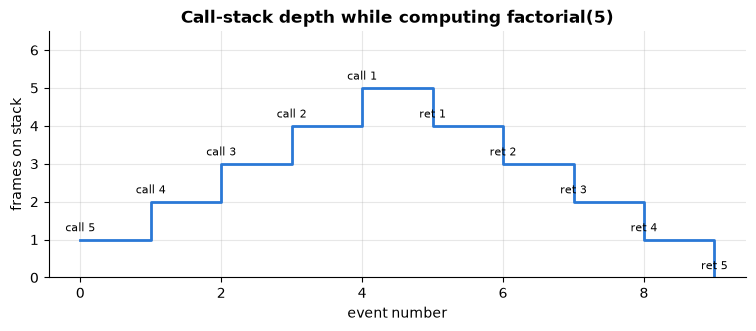

In [11]:
trace = []                                  # (event, n, depth) records for the plot below

def factorial(n, depth=0):
    print("    " * depth + f"→ factorial({n})")
    trace.append(("call", n, depth + 1))
    if n <= 1:                              # base case
        result = 1
    else:                                   # recursive case: smaller problem, then combine
        result = n * factorial(n - 1, depth + 1)
    print("    " * depth + f"← factorial({n}) returns {result}")
    trace.append(("return", n, depth))
    return result

assert factorial(5) == math.factorial(5)

depths = [d for _, _, d in trace]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.step(range(len(depths)), depths, where="post", color=PALETTE[0])
for i, (ev, n, d) in enumerate(trace):
    ax.annotate(f"{'call' if ev == 'call' else 'ret'} {n}", (i, d), textcoords="offset points",
                xytext=(0, 6), ha="center", fontsize=8)
ax.set(title="Call-stack depth while computing factorial(5)", xlabel="event number", ylabel="frames on stack", ylim=(0, 6.5))
plt.show()

**What just happened?** The indented printout is the call stack: five calls go down (push) until the base case `factorial(1)`, then five returns come back up (pop), each multiplying by its own n. The step plot shows the stack depth rising to 5 frames and falling back to 0. Time is Θ(n) (n calls doing O(1) work each) and space is **Θ(n)** because n frames are alive at the deepest point.

### Recursion trees
When a function makes *more than one* recursive call, the calls form a **recursion tree**. Naive Fibonacci, fib(n) = fib(n−1) + fib(n−2), is the classic example. Let's draw the tree for fib(5) with networkx (our own simple layout).

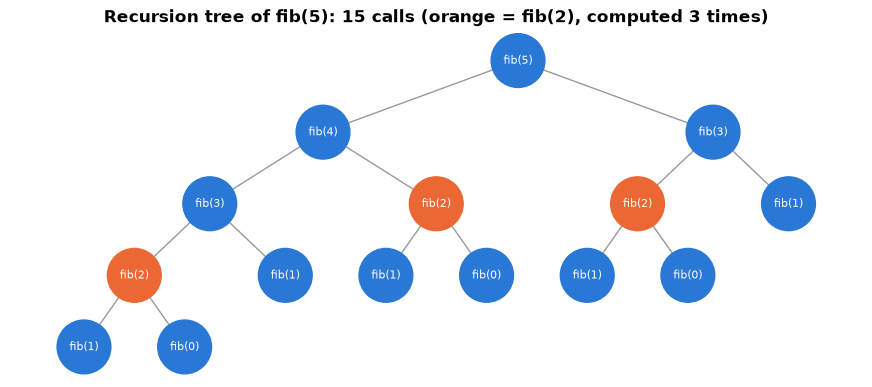

fib(5) makes      15 calls
fib(10) makes     177 calls
fib(20) makes  21,891 calls
fib(25) makes 242,785 calls


In [12]:
import networkx as nx

def build_fib_tree(n, G, counter):
    """Add the call fib(n) and its children to G; return this node's id."""
    node = counter[0]; counter[0] += 1
    G.add_node(node, label=f"fib({n})", n=n)
    if n >= 2:
        for child_n in (n - 1, n - 2):
            child = build_fib_tree(child_n, G, counter)
            G.add_edge(node, child)
    return node

def tree_layout(G, root):
    """Leaves get consecutive x positions; parents sit above the middle of their children."""
    pos, next_x = {}, [0]
    def place(v, depth):
        kids = list(G.successors(v))
        if not kids:
            pos[v] = (next_x[0], -depth); next_x[0] += 1
        else:
            for k in kids:
                place(k, depth + 1)
            pos[v] = (sum(pos[k][0] for k in kids) / len(kids), -depth)
    place(root, 0)
    return pos

G = nx.DiGraph()
root = build_fib_tree(5, G, [0])
pos = tree_layout(G, root)
colors = [PALETTE[1] if G.nodes[v]["n"] == 2 else PALETTE[0] for v in G]   # highlight repeated fib(2)
fig, ax = plt.subplots(figsize=(11, 4.5))
nx.draw(G, pos, ax=ax, labels=nx.get_node_attributes(G, "label"), node_color=colors,
        node_size=1500, font_size=8, font_color="white", arrows=False, edge_color="#999999")
ax.set_title(f"Recursion tree of fib(5): {G.number_of_nodes()} calls (orange = fib(2), computed 3 times)")
plt.show()

def fib_calls(n):                 # number of calls naive fib makes
    return 1 if n < 2 else 1 + fib_calls(n - 1) + fib_calls(n - 2)
fibs = [0, 1]
for _ in range(30): fibs.append(fibs[-1] + fibs[-2])
for n in [5, 10, 20, 25]:
    assert fib_calls(n) == 2 * fibs[n + 1] - 1          # closed form: 2·F(n+1) − 1
    print(f"fib({n}) makes {fib_calls(n):>7,} calls")

**What just happened?** fib(5) makes **15 calls** and recomputes the same sub-problems again and again (fib(2) three times, fib(3) twice). In general naive fib(n) makes 2·F(n+1) − 1 calls, which grows like φⁿ with φ ≈ 1.618 (exponential): fib(25) already makes 242,785 calls. Time is Θ(φⁿ); space is only Θ(n), because at any moment only one root-to-leaf path of the tree is on the stack.

### Tail recursion and the recursion limit
A call is a **tail call** if it is the very last thing the function does (nothing left to compute after it returns). Some languages (Scheme, and optionally C compilers) reuse the frame for tail calls, so tail recursion runs in O(1) space. **Python does not do tail-call optimisation**, by design (Guido van Rossum wanted full tracebacks), so every call still costs a frame. To avoid crashing the interpreter, Python limits the depth: `sys.getrecursionlimit()` is 1000 by default.

In [13]:
def fact_tail(n, acc=1):
    """Tail-recursive factorial: the recursive call is the last action."""
    if n <= 1:
        return acc
    return fact_tail(n - 1, acc * n)      # nothing left to do after this returns

def fact_loop(n):
    """What a tail-call optimiser would turn fact_tail into: a loop, O(1) stack."""
    acc = 1
    while n > 1:
        acc, n = acc * n, n - 1
    return acc

print("recursion limit:", sys.getrecursionlimit())
assert fact_tail(500) == fact_loop(500) == math.factorial(500)
try:
    fact_tail(5000)                        # deeper than the limit, even though it is tail recursive
except RecursionError as e:
    print("fact_tail(5000) failed with RecursionError:", e)
big = fact_loop(5000)
print(f"fact_loop(5000) works fine: about {math.log10(big):,.0f} decimal digits ({big.bit_length():,} bits)")

recursion limit: 1000
fact_tail(5000) failed with RecursionError: maximum recursion depth exceeded
fact_loop(5000) works fine: about 16,326 decimal digits (54,233 bits)


**What just happened?** The tail-recursive version works for n = 500 but raises **RecursionError** for n = 5000, proving Python keeps one frame per call even for tail calls. The loop version has no such limit. You *can* raise the limit with `sys.setrecursionlimit`, but going too high can crash the interpreter (the C stack overflows), so in Python the standard advice is: **convert deep recursion into a loop or use an explicit stack**.

> ⚠️ **Common mistake:** forgetting the base case, or a recursive call that does not shrink the input (e.g. `f(n)` calling `f(n)`), leads to infinite recursion and a RecursionError.

### Memoisation preview
Naive fib recomputes sub-problems. **Memoisation** stores each answer the first time it is computed, so every sub-problem is solved once. This is the gateway to **dynamic programming** ([09 · Dynamic programming](09_dynamic_programming.ipynb) in this module).

In [14]:
from functools import lru_cache

calls = {"naive": 0, "memo": 0}
def fib_naive(n):
    calls["naive"] += 1
    return n if n < 2 else fib_naive(n - 1) + fib_naive(n - 2)

@lru_cache(maxsize=None)           # remembers every (argument → result) pair
def fib_memo(n):
    calls["memo"] += 1
    return n if n < 2 else fib_memo(n - 1) + fib_memo(n - 2)

t0 = time.perf_counter(); a = fib_naive(27); t_naive = time.perf_counter() - t0
t0 = time.perf_counter(); b = fib_memo(27);  t_memo = time.perf_counter() - t0
assert a == b == fibs[27]
print(f"fib(27) = {a}")
print(f"naive: {calls['naive']:>7,} calls, {t_naive * 1000:8.1f} ms")
print(f"memo : {calls['memo']:>7,} calls, {t_memo * 1000:8.3f} ms")

fib(27) = 196418
naive: 635,621 calls,    360.6 ms
memo :      28 calls,    0.177 ms


**What just happened?** Both return 196418, but naive recursion made 635,621 calls while the memoised version made only **28** (one per value 0…27). Memoisation turned Θ(φⁿ) time into Θ(n) time at the cost of Θ(n) memory: the time vs. space trade-off again.

---
## 8. Recurrence relations

> 💡 **In plain English:** a recurrence is an equation for the running time of a recursive algorithm, and there are recipes for solving it.

A recursive algorithm's running time is naturally described by a **recurrence**: an equation that defines T(n) in terms of T on smaller inputs.

| Algorithm | Recurrence | Solution |
|---|---|---|
| factorial / linear recursion | T(n) = T(n−1) + c | Θ(n) |
| binary search | T(n) = T(n/2) + c | Θ(log n) |
| merge sort | T(n) = 2T(n/2) + cn | Θ(n log n) |
| naive fib | T(n) = T(n−1) + T(n−2) + c | Θ(φⁿ) |
| Strassen matrix multiply | T(n) = 7T(n/2) + cn² | Θ(n^log₂7) ≈ Θ(n^2.807) |

Three methods to solve them:

### (a) Substitution method: guess, then prove by induction
Claim: T(n) = 2T(n/2) + n with T(1) = 1 satisfies T(n) ≤ c·n log₂ n + n for n a power of 2.
*Inductive step:* assume it for n/2. Then T(n) = 2T(n/2) + n ≤ 2(c·(n/2)·log₂(n/2) + n/2) + n = c·n(log₂ n − 1) + 2n = c·n log₂ n − cn + 2n ≤ c·n log₂ n + n whenever c ≥ 1. With c = 1 we even get equality: **T(n) = n log₂ n + n**.

### (b) Recursion-tree method: add up the work level by level
For T(n) = 2T(n/2) + n:
```
level 0:            n                       work n
level 1:      n/2       n/2                 work 2 · n/2 = n
level 2:   n/4  n/4  n/4  n/4               work 4 · n/4 = n
  ...                                        ...
level log₂n: n leaves of size 1             work n
```
There are log₂ n + 1 levels, each doing n work, so T(n) = n(log₂ n + 1) = **Θ(n log n)**.

### (c) The Master theorem
For recurrences of the form **T(n) = a·T(n/b) + f(n)** with a ≥ 1, b > 1: compare f(n) with the **watershed function n^(log_b a)** (the total work at the leaves).

| Case | Condition | Result | Intuition |
|---|---|---|---|
| 1 | f(n) = O(n^(log_b a − ε)) for some ε > 0 | T(n) = Θ(n^(log_b a)) | leaves dominate |
| 2 | f(n) = Θ(n^(log_b a) · logᵏ n), k ≥ 0 | T(n) = Θ(n^(log_b a) · log^(k+1) n) | every level equal |
| 3 | f(n) = Ω(n^(log_b a + ε)) and a·f(n/b) ≤ c·f(n) for some c < 1 (regularity) | T(n) = Θ(f(n)) | root dominates |

**Worked cases:**
- **Binary search** T(n) = T(n/2) + 1: a = 1, b = 2, n^(log₂1) = n⁰ = 1 = f(n) → case 2 (k = 0) → **Θ(log n)**.
- **Merge sort** T(n) = 2T(n/2) + n: n^(log₂2) = n = f(n) → case 2 → **Θ(n log n)**.
- **Strassen** T(n) = 7T(n/2) + n²: n^(log₂7) ≈ n^2.807, and n² = O(n^(2.807 − ε)) → case 1 → **Θ(n^2.807)**, beating the naive divide-and-conquer T(n) = 8T(n/2) + n² = Θ(n³).
- **Root-heavy** T(n) = 2T(n/2) + n²: n^(log₂2) = n, f = n² = Ω(n^(1+ε)); regularity 2(n/2)² = n²/2 ≤ ½·n² ✓ → case 3 → **Θ(n²)**.

When it does **not** apply: T(n) = T(n−1) + n (not of the form n/b; it is Θ(n²)), or T(n) = 2T(n/2) + n/log n (f falls in the gap between cases; the answer is Θ(n log log n)).

In [15]:
def pretty(e, logpow=0):
    """Format n^e · log^logpow n nicely, e.g. 'n log n', 'n^2.807', 'log n'."""
    if abs(e) < 1e-12:   npart = ""
    elif abs(e - 1) < 1e-12: npart = "n"
    elif abs(e - round(e)) < 1e-12: npart = f"n^{round(e)}"
    else:                npart = f"n^{e:.3f}"
    lpart = "" if logpow == 0 else ("log n" if logpow == 1 else f"log^{logpow} n")
    return "Θ(" + (" ".join(x for x in (npart, lpart) if x) or "1") + ")"

def master(a, b, k, p=0):
    """Master theorem for T(n) = a T(n/b) + Θ(n^k log^p n), p >= 0. Returns (case, answer)."""
    crit = math.log(a, b)                                   # watershed exponent log_b(a)
    if abs(k - crit) < 1e-12:                               # case 2: every level does the same work
        return 2, pretty(crit, p + 1)
    if k < crit:                                            # case 1: leaves dominate
        return 1, pretty(crit)
    return 3, pretty(k, p)                                  # case 3: root dominates (regularity holds for polynomial f)

cases = [("binary search", 1, 2, 0), ("merge sort", 2, 2, 1), ("Strassen", 7, 2, 2),
         ("naive D&C matrix multiply", 8, 2, 2), ("root-heavy 2T(n/2)+n²", 2, 2, 2),
         ("Karatsuba multiplication", 3, 2, 1)]
rows = []
for name, a, b, k in cases:
    case, ans = master(a, b, k)
    rows.append({"algorithm": name, "recurrence": f"T(n) = {a}T(n/{b}) + n^{k}",
                 "log_b a": round(math.log(a, b), 3), "case": case, "solution": ans})
pd.DataFrame(rows)

,algorithm,recurrence,log_b a,case,solution
0,binary search,T(n) = 1T(n/2) + n^0,0.000,2,Θ(log n)
1,merge sort,T(n) = 2T(n/2) + n^1,1.000,2,Θ(n log n)
2,Strassen,T(n) = 7T(n/2) + n^2,2.807,1,Θ(n^2.807)
3,naive D&C matrix multiply,T(n) = 8T(n/2) + n^2,3.000,1,Θ(n^3)
4,root-heavy 2T(n/2)+n²,T(n) = 2T(n/2) + n^2,1.000,3,Θ(n^2)
5,Karatsuba multiplication,T(n) = 3T(n/2) + n^1,1.585,1,Θ(n^1.585)


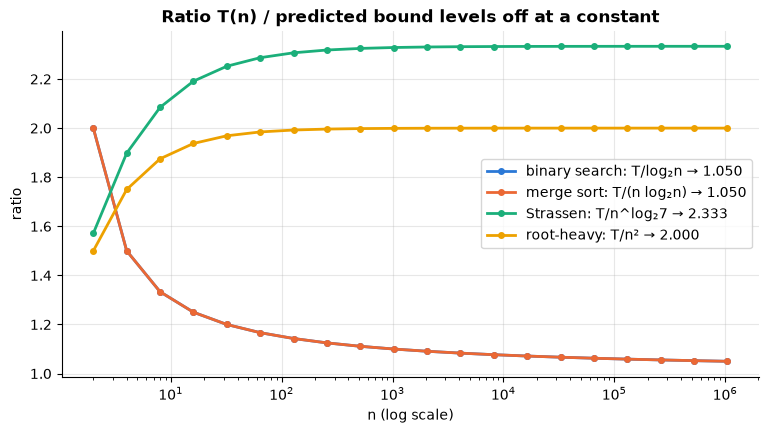

In [16]:
# Check numerically: evaluate each recurrence exactly for n = 2^1..2^20 and divide by the predicted answer.
from functools import lru_cache

def make_T(a, k):
    @lru_cache(maxsize=None)
    def T(n):
        return 1 if n <= 1 else a * T(n // 2) + n**k
    return T

checks = {
    "binary search: T/log₂n":     (make_T(1, 0), lambda n: math.log2(n)),
    "merge sort: T/(n log₂n)":    (make_T(2, 1), lambda n: n * math.log2(n)),
    "Strassen: T/n^log₂7":        (make_T(7, 2), lambda n: n ** math.log2(7)),
    "root-heavy: T/n²":           (make_T(2, 2), lambda n: n ** 2),
}
ns = [2**i for i in range(1, 21)]
fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, (T, g)), col in zip(checks.items(), PALETTE):
    ratio = [T(n) / g(n) for n in ns]
    ax.semilogx(ns, ratio, "o-", ms=4, color=col, label=f"{name} → {ratio[-1]:.3f}")
ax.set(title="Ratio T(n) / predicted bound levels off at a constant", xlabel="n (log scale)", ylabel="ratio")
ax.legend(); plt.show()

T_merge = checks["merge sort: T/(n log₂n)"][0]
assert all(T_merge(n) == n * int(math.log2(n)) + n for n in ns)   # the exact solution from the substitution method

**What just happened?** For each recurrence we computed T(n) exactly and divided by the Master-theorem prediction. All four ratios level off at a constant: for binary search and merge sort the ratio is (log₂ n + 1)/log₂ n (the two curves coincide), which creeps down towards 1 (1.05 at n = 2²⁰); Strassen settles at 7/3 ≈ 2.33 and the root-heavy case at 2, which is exactly what Θ promises: same growth, different constant. The final assert confirms the merge-sort recurrence equals **n log₂ n + n** exactly, as we proved by substitution.

> 🎓 **Exam / interview tip:** for the Master theorem, always write down (1) a, b, f(n), (2) n^(log_b a), (3) which case and why, and for case 3 (4) check the regularity condition.

---
## 9. Complexity of Python's built-in data structures

> 💡 **In plain English:** every operation on a list, dict, set or deque has a known cost; picking the right container is the easiest speed-up.

Knowing these costs prevents the most common performance bugs in Python. (Source: the CPython "TimeComplexity" wiki page; n = size of the container, k = size of the argument/slice.)

| Operation | `list` | `dict` | `set` | `collections.deque` |
|---|---|---|---|---|
| access by index `x[i]` | O(1) | — | — | O(1) at the ends, O(n) in the middle |
| look up by key `d[k]` / membership `x in c` | O(n) | O(1) avg, O(n) worst | O(1) avg, O(n) worst | O(n) |
| append at the end | O(1) amortized | O(1) avg (insert) | O(1) avg (add) | O(1) |
| add / remove at the front | O(n) (`insert(0, x)`, `pop(0)`) | — | — | **O(1)** (`appendleft`, `popleft`) |
| pop from the end | O(1) | `popitem()` O(1) | `pop()` O(1) | O(1) |
| insert / delete in the middle | O(n) | delete by key O(1) avg | `remove` / `discard` O(1) avg | O(n) |
| iterate over all items | O(n) | O(n) | O(n) | O(n) |
| copy | O(n) | O(n) | O(n) | O(n) |
| `len()` | O(1) | O(1) | O(1) | O(1) |
| sort | O(n log n) | — | — | — |
| slice `x[a:b]` | O(k) | — | — | — |
| union / intersection | — | `d1 \| d2` O(len d1 + len d2) | `s \| t` O(len s + len t), `s & t` O(min(len s, len t)) avg | — |
| `min` / `max` | O(n) | O(n) | O(n) | O(n) |

"avg" means on average over hash values; the O(n) worst case happens only when many keys collide (notebook 04 shows how).

In [17]:
from collections import deque

n = 50_000
def drain_list(m):
    a = list(range(m))
    while a:
        a.pop(0)                # O(n) each: shifts every element left
def drain_deque(m):
    d = deque(range(m))
    while d:
        d.popleft()             # O(1) each

for m in [10_000, 40_000]:
    tl = min(timeit.repeat(lambda: drain_list(m), number=1, repeat=3))
    td = min(timeit.repeat(lambda: drain_deque(m), number=1, repeat=3))
    print(f"empty a queue of {m:>6,} items from the front: list.pop(0) {tl * 1000:7.1f} ms | deque.popleft() {td * 1000:5.1f} ms")

big_list = list(range(n)); big_set = set(big_list); missing = -1
tl = min(timeit.repeat(lambda: missing in big_list, number=200, repeat=3)) / 200
ts = min(timeit.repeat(lambda: missing in big_set, number=200, repeat=3)) / 200
print(f"membership test on {n:,} items: list {tl * 1e6:8.1f} µs | set {ts * 1e6:6.3f} µs  ({tl / ts:,.0f}× faster)")

empty a queue of 10,000 items from the front: list.pop(0)    30.2 ms | deque.popleft()   1.2 ms


empty a queue of 40,000 items from the front: list.pop(0)   634.6 ms | deque.popleft()   5.6 ms


membership test on 50,000 items: list   2712.1 µs | set  0.143 µs  (18,920× faster)


**What just happened?** Draining a queue with `list.pop(0)` is O(n²) overall (4× more items took far more than 4× longer; O(n²) predicts 16×, and memory effects can add more), while `deque.popleft()` stays linear. Membership in a set was thousands of times faster than scanning a list. Two one-line changes, `list → deque` for queues and `list → set` for membership, fix a huge share of real-world Python slowness.

> ⚠️ **Common mistake:** `if x in my_list:` inside a loop over another big list. That is O(n·m). Convert `my_list` to a set once, before the loop.

---
## 10. 🔗 How this connects to modern AI

> 💡 **In plain English:** the same growth-rate thinking explains why long prompts are expensive for LLMs and why vector search needs indexes.

- **Transformers are O(n²) in sequence length.** Self-attention compares every token with every other token, so doubling the context length quadruples attention cost. Techniques like FlashAttention (same O(n²) arithmetic, far less memory traffic), sliding-window attention and KV caching exist precisely because of this. See [LLM inference optimisation](../../08_LLM/13_inference_optimization.ipynb) and the [transformer architecture](../../05_Deep_Learning/05_transformers_architecture.ipynb).
- **Nearest-neighbour search.** Brute-force similarity search over N embeddings of dimension d costs O(N·d) per query; vector databases use approximate indexes (HNSW, IVF) to get roughly logarithmic or sub-linear query time. See [vector databases](../../22_ML_System_Design/05_vector_databases.ipynb).
- **Training cost scales with data × parameters.** Estimating "will this finish overnight?" is exactly the n = 10⁶ table from section 3.
- **Recursion is everywhere in ML code:** decision trees are built recursively, parse trees and tree search (MCTS in AlphaZero) are recursive, and memoisation is the same idea as caching repeated LLM calls or computed features.
- **Amortized dynamic arrays** sit under every `list.append` in your data pipelines and under the growing KV cache in LLM serving systems.

---
## Recap
- An **algorithm** is a finite, definite procedure; we analyse it in the **RAM model** by counting simple operations.
- **O** is an upper bound, **Ω** a lower bound, **Θ** a tight bound, each with constants c and n₀; **little-o** is a strict upper bound (ratio → 0).
- Growth order: 1 < log n < n < n log n < n² < n³ < 2ⁿ < n!. For n = 10⁶, n² is hours and 2ⁿ is forever.
- **Best/average/worst** case are different functions; **amortized** cost averages a *sequence* (dynamic array doubling: O(1) per append).
- **Space** counts auxiliary memory, including the recursion stack; you can often trade memory for time.
- Measure with **`timeit`** (min of repeats) and read exponents off **log-log** slopes.
- Recursion needs a **base case** and **progress**; Python has **no tail-call optimisation** and a recursion limit of 1000; memoisation removes repeated work.
- Solve recurrences by **substitution**, **recursion trees** or the **Master theorem** (compare f(n) with n^(log_b a)).
- Use `set`/`dict` for membership and `deque` for queues.

## Practice problems

**1. (Easy, conceptual)** True or false, with a reason: (a) 5n + 3 = O(n²); (b) n² = O(n); (c) 2ⁿ⁺¹ = Θ(2ⁿ); (d) log₂ n = Θ(log₁₀ n).

<details><summary>Show solution</summary>

(a) **True** — an upper bound need not be tight (c = 8, n₀ = 1).
(b) **False** — n²/n = n is unbounded, so no constant c works.
(c) **True** — 2ⁿ⁺¹ = 2·2ⁿ, constant factor 2.
(d) **True** — log₂ n = log₁₀ n / log₁₀ 2 ≈ 3.32·log₁₀ n; the base of a logarithm is only a constant factor, which is why we often just write log n.

</details>

**2. (Easy)** Give c and n₀ proving 7n² + 20n = O(n²).

<details><summary>Show solution</summary>

Take c = 8: 7n² + 20n ≤ 8n² ⇔ 20n ≤ n² ⇔ n ≥ 20, so **c = 8, n₀ = 20**. (Or c = 27, n₀ = 1, since 20n ≤ 20n² for n ≥ 1.)

</details>

**3. (Easy, coding)** What is the time complexity of `i = 1; while i < n: i *= 2`? Write a function counting its iterations and check your formula.

<details><summary>Show solution</summary>

i takes the values 1, 2, 4, …, so the loop runs ⌈log₂ n⌉ times: **Θ(log n)**.
```python
def count_steps(n):
    """How many times does the body of this loop run?   i = 1; while i < n: i *= 2"""
    steps, i = 0, 1
    while i < n:
        i *= 2
        steps += 1
    return steps
```
Tested for every n from 2 to 4999 against `math.ceil(math.log2(n))`.

</details>

**4. (Medium, conceptual)** Solve with the Master theorem: (a) T(n) = 4T(n/2) + n, (b) T(n) = 4T(n/2) + n², (c) T(n) = 4T(n/2) + n³, (d) T(n) = 2T(n/4) + √n.

<details><summary>Show solution</summary>

n^(log_b a): (a)–(c) n^(log₂4) = n²; (d) n^(log₄2) = n^0.5.
(a) f = n = O(n^(2−ε)) → case 1 → **Θ(n²)**.
(b) f = n² = Θ(n²) → case 2 → **Θ(n² log n)**.
(c) f = n³ = Ω(n^(2+ε)), regularity 4(n/2)³ = n³/2 ≤ ½n³ ✓ → case 3 → **Θ(n³)**.
(d) f = √n = Θ(n^0.5) → case 2 → **Θ(√n log n)**.

</details>

**5. (Medium, conceptual)** A dynamic array grows its capacity by 1.5× when full. Is append still O(1) amortized? What about growing by +1000 each time?

<details><summary>Show solution</summary>

**1.5×: yes.** Copies form a geometric series n/1.5 + n/1.5² + … ≤ n · (1/(1.5−1)) = 2n, so the total is O(n) and each append is O(1) amortized. Any constant factor > 1 works; smaller factors waste less memory but copy more often.
**+1000: no.** Resizes happen every 1000 appends and copy 1000, 2000, 3000, … elements: total ≈ n²/2000 = Θ(n²), so the amortized cost per append is Θ(n).

</details>

**6. (Medium, coding)** Write a recursive `power(x, n)` that uses O(log n) multiplications. State and solve its recurrence.

<details><summary>Show solution</summary>

```python
def power(x, n):
    """Compute x**n with O(log n) multiplications (fast exponentiation)."""
    if n == 0:                      # base case
        return 1
    half = power(x, n // 2)         # ONE recursive call on n/2: T(n) = T(n/2) + O(1)
    if n % 2 == 0:
        return half * half
    return half * half * x
```
Recurrence T(n) = T(n/2) + O(1) → Master theorem case 2 with a = 1, b = 2 → **Θ(log n)**. Space Θ(log n) for the stack. (Calling `power(x, n // 2)` *twice* would give T(n) = 2T(n/2) + O(1) = Θ(n): a classic trap.)

</details>

**7. (Easy, coding)** Write a recursive function that sums the digits of a non-negative integer. What are the base case, time and space?

<details><summary>Show solution</summary>

```python
def sum_digits(n):
    """Recursive sum of the decimal digits of a non-negative integer."""
    if n < 10:                       # base case: a single digit
        return n
    return n % 10 + sum_digits(n // 10)   # last digit + digits of the rest
```
Base case: a single digit (n < 10). Each call removes one digit, so for a number with d = ⌊log₁₀ n⌋ + 1 digits: time Θ(d) = Θ(log n) and stack space Θ(log n).

</details>

**8. (Hard, coding, interview classic)** Given a list and k, return the maximum of every contiguous window of size k. Write the O(n·k) version and an O(n) version, and test them against each other.

<details><summary>Show solution</summary>

```python
from collections import deque

def sliding_max_naive(a, k):
    return [max(a[i:i + k]) for i in range(len(a) - k + 1)]       # O(n·k)

def sliding_max(a, k):
    """Maximum of every window of size k in O(n) using a deque of indices."""
    dq, out = deque(), []            # dq holds indices; their values are decreasing
    for i, x in enumerate(a):
        while dq and a[dq[-1]] <= x: # smaller elements can never be a future max
            dq.pop()
        dq.append(i)
        if dq[0] <= i - k:           # front index left the window
            dq.popleft()
        if i >= k - 1:
            out.append(a[dq[0]])
    return out
```
Each index is pushed and popped at most once, so the deque version is **O(n)** amortized time and O(k) space, even though there is a `while` inside the `for`. This "monotonic deque" is a great example of amortized analysis.

</details>

## Further reading
- Cormen, Leiserson, Rivest, Stein, *Introduction to Algorithms* (CLRS, 4th ed., 2022): ch. 2 (getting started), ch. 3 (characterising running times), ch. 4 (divide and conquer, Master theorem), ch. 16 (amortized analysis).
- Skiena, *The Algorithm Design Manual* (3rd ed.), ch. 2 (algorithm analysis).
- Sedgewick & Wayne, *Algorithms* (4th ed.), section 1.4 (analysis of algorithms, doubling experiments).
- GeeksforGeeks: [Analysis of Algorithms](https://www.geeksforgeeks.org/analysis-of-algorithms/) and [Recursion](https://www.geeksforgeeks.org/recursion/).
- MIT OpenCourseWare 6.006 *Introduction to Algorithms*: https://ocw.mit.edu/courses/6-006-introduction-to-algorithms-spring-2020/
- Python wiki, *TimeComplexity*: https://wiki.python.org/moin/TimeComplexity

## Next notebook
➡️ [02 · Arrays, Strings and Problem-Solving Techniques](02_arrays_strings_and_techniques.ipynb): two pointers, sliding windows, prefix sums, Kadane's algorithm and bit tricks.